# Exploring `bee-mic`: 3D Acoustic Pollinator Tracking

This notebook walks through the core workflow of `bee-mic`:
1. **Array Setup:** Configuring the perimeter microphone array.
2. **Single-Bee Flight & Audio Playback:** Synthesizing a moving wingbeat buzz and listening to a microphone channel.
3. **3D Localization & Tracking:** Running hierarchical SRP-PHAT with energy gating and a kinematic Kalman filter.
4. **Multi-Bee Mixing:** Combining two overlapping sources with identical wingbeat frequencies using `pad_sum`.

In [8]:
# Interactive rotatable 3D plots (requires ipympl)
%matplotlib widget

# Automatically pick up edits made to src/bee_mic/ without restarting the kernel
%load_ext autoreload
%autoreload 2

import numpy as np
import matplotlib.pyplot as plt

from IPython.display import Audio, display
from scipy.spatial.distance import cdist
from scipy.optimize import linear_sum_assignment

from bee_mic.simulation import SourceSimulator
from bee_mic.geometry import ArrayGeometry
from bee_mic.dsp import AcousticSolver
from bee_mic.tracking import KinematicKalmanFilter
from bee_mic.util import pad_sum
from bee_mic.visualization import (plot_flight_path_3d, plot_spatial_error_heatmap, plot_3d_geometry,
                                   plot_cross_correlation, plot_gcc_phat_diagnostic)

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


## 1. Microphone Array Setup

We start by initializing `SourceSimulator` at 48 kHz and creating a default `ArrayGeometry.perimeter_array()`.

Loaded array with 5 microphones:
  Mic 0: x=-1.00 m, y=-1.00 m, z=+0.15 m
  Mic 1: x=+1.00 m, y=-1.00 m, z=+0.85 m
  Mic 2: x=+1.00 m, y=+1.00 m, z=+0.15 m
  Mic 3: x=-1.00 m, y=+1.00 m, z=+0.85 m
  Mic 4: x=+0.00 m, y=+0.00 m, z=+0.50 m


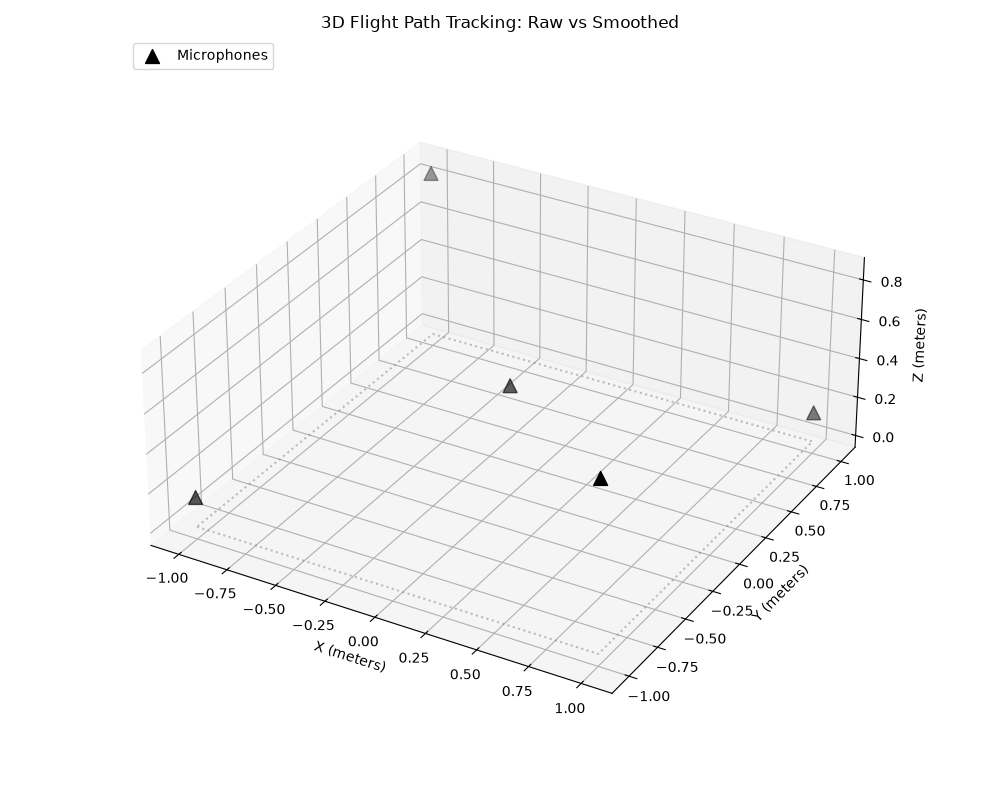

Text(0.5, 0.92, 'Mic positions')

In [9]:
FS = 48000
sim = SourceSimulator(fs=FS)
mics = ArrayGeometry.perimeter_array()
solver = AcousticSolver(fs=FS)

print(f"Loaded array with {mics.shape[0]} microphones:")
for idx, pos in enumerate(mics):
    print(f"  Mic {idx}: x={pos[0]:+.2f} m, y={pos[1]:+.2f} m, z={pos[2]:+.2f} m")

plot_flight_path_3d([], [], [], mic_positions=mics)
plt.title("Mic positions")

## 2. Single-Bee Flight & Audio Playback

Simulate a single pollinator flying in a straight line across the array at a 250 Hz fundamental wingbeat frequency. Use the audio player below to listen to what Mic 0 hears.

In [10]:
duration = 0.6  # seconds
sig = sim.generate_pollinator_buzz(duration=duration, f0=250.0)

start_pos = np.array([-0.8, -0.6, 0.4])
end_pos = np.array([0.8, 0.6, 0.7])
true_traj = np.linspace(start_pos, end_pos, len(sig))

rx_moving = sim.simulate_moving_propagation(true_traj, mics, sig, snr_db=25)

print("Mic 0 recording (simulated 250 Hz buzz, 25 dB SNR):")
display(Audio(rx_moving[0], rate=FS))

Mic 0 recording (simulated 250 Hz buzz, 25 dB SNR):


## 3. 3D Localization & Kalman Tracking

We slice the recording into overlapping 40 ms windows (20 ms step), apply an RMS energy gate to skip initial propagation-delay silence, localize with `srp_phat_hierarchical`, and smooth the path with `KinematicKalmanFilter`.

T:   40ms | Raw Err:   7.2cm | Smooth Err:   7.1cm
T:   60ms | Raw Err:   3.8cm | Smooth Err:   3.6cm
T:   80ms | Raw Err:   4.7cm | Smooth Err:   4.7cm
T:  100ms | Raw Err:   0.6cm | Smooth Err:   0.7cm
T:  120ms | Raw Err:   1.6cm | Smooth Err:   1.6cm
T:  140ms | Raw Err:   2.5cm | Smooth Err:   2.5cm
T:  160ms | Raw Err:   1.6cm | Smooth Err:   1.5cm
T:  180ms | Raw Err:   0.6cm | Smooth Err:   0.6cm
T:  200ms | Raw Err:   0.3cm | Smooth Err:   0.3cm
T:  220ms | Raw Err:   1.3cm | Smooth Err:   1.3cm
T:  240ms | Raw Err:   2.2cm | Smooth Err:   2.2cm
T:  260ms | Raw Err:   3.1cm | Smooth Err:   3.1cm
T:  280ms | Raw Err:   0.9cm | Smooth Err:   0.9cm
T:  300ms | Raw Err:   0.0cm | Smooth Err:   0.1cm
T:  320ms | Raw Err:   0.9cm | Smooth Err:   0.9cm
T:  340ms | Raw Err:   1.9cm | Smooth Err:   1.9cm
T:  360ms | Raw Err:   2.8cm | Smooth Err:   2.8cm
T:  380ms | Raw Err:   1.2cm | Smooth Err:   1.2cm
T:  400ms | Raw Err:   0.3cm | Smooth Err:   0.3cm
T:  420ms | Raw Err:   0.6cm | 

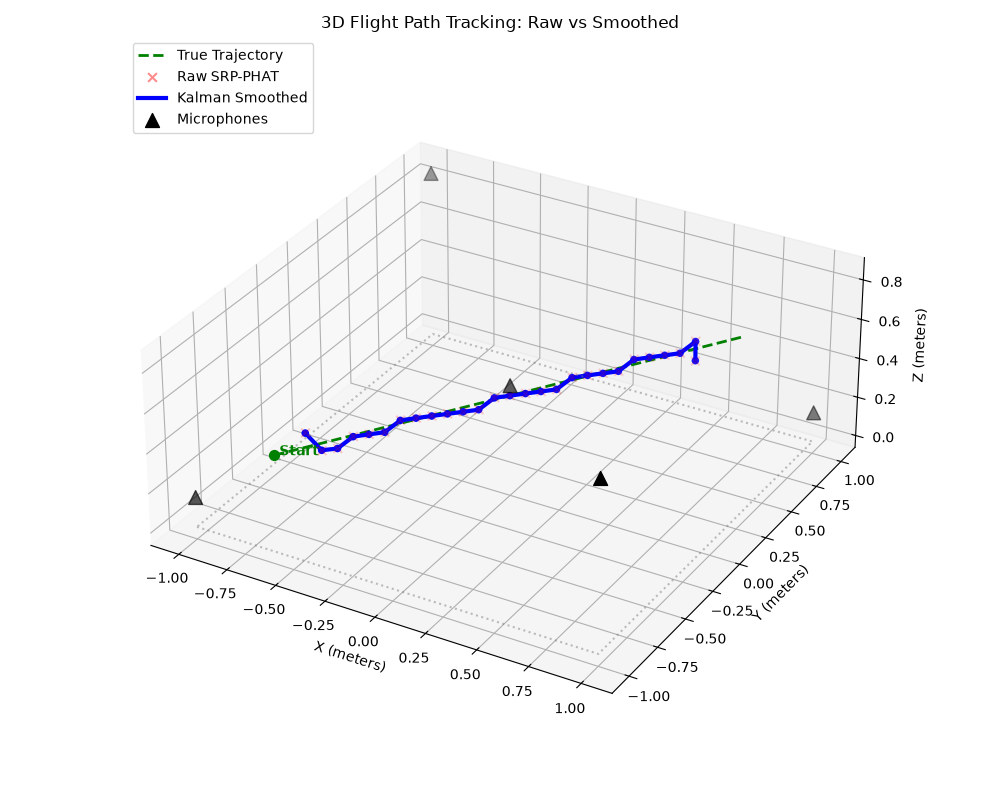

In [13]:
# a. Generate trajectory
start_pos, end_pos = np.array([-0.8, -0.8, 0.3]), np.array([0.8, 0.8, 0.6])
trajectory = np.linspace(start_pos, end_pos, len(sig))

# b. Simulate moving audio
rx_moving = sim.simulate_moving_propagation(trajectory, mics, sig, snr_db=20)

# Calculate an energy threshold based on the whole recording
# (or set a fixed threshold empirically)
global_rms = np.sqrt(np.mean(rx_moving ** 2))
energy_threshold = global_rms * 0.25  # adjust multiplier as needed

# c. Track with SRP-PHAT and Kalman Filter
solver = AcousticSolver(fs=48000)
kf = KinematicKalmanFilter(dt=0.02, initial_pos=start_pos, process_noise=8.0, measurement_noise=0.15)

window_samples = int(0.04 * sim.fs)
step_samples = int(0.02 * sim.fs)

raw_positions, smoothed_positions, actual_positions = [], [], []

for start_idx in range(0, rx_moving.shape[1] - window_samples, step_samples):
    audio_chunk = rx_moving[:, start_idx:start_idx + window_samples]

    mid_time_emit = (start_idx + window_samples / 2) / sim.fs
    if int(mid_time_emit * sim.fs) >= len(sig):
        break

    # True position
    true_mid_pos = trajectory[int(mid_time_emit * sim.fs)]
    actual_positions.append(true_mid_pos)

    # Kalman prediction
    kf.predict()

    # Check if audio chunk has sufficient power for analysis
    frame_rms = np.sqrt(np.mean(audio_chunk ** 2))
    if frame_rms > energy_threshold:
        raw_pos, _ = solver.srp_phat(audio_chunk, mics, bounds=([-1, -1, 0], [1, 1, 1]), num_targets=1# 1. Generate trajectory)
        raw_positions.append(raw_pos[0])

        smoothed_pos = kf.update(raw_pos[0])
        smoothed_positions.append(smoothed_pos)

        print(
            f"T: {(start_idx / sim.fs) * 1000:4.0f}ms | Raw Err: {np.linalg.norm(true_mid_pos - raw_pos[0]) * 100:5.1f}cm | Smooth Err: {np.linalg.norm(true_mid_pos - smoothed_pos) * 100:5.1f}cm")
    else:
        raw_positions.append(np.full(3, np.nan))
        smoothed_positions.append(np.full(3, np.nan))

plot_flight_path_3d(actual_positions, raw_positions, smoothed_positions, mic_positions=mics)


## 4. Multi-Bee Mixing (Overlapping Frequencies)

When two bees of the same species share the same 250 Hz wingbeat frequency, bandpass filtering cannot separate them. Here we mix two stationary sources of slightly different propagation lengths using `pad_sum`, inspect the GCC-PHAT cross-correlation, and localize both targets simultaneously.

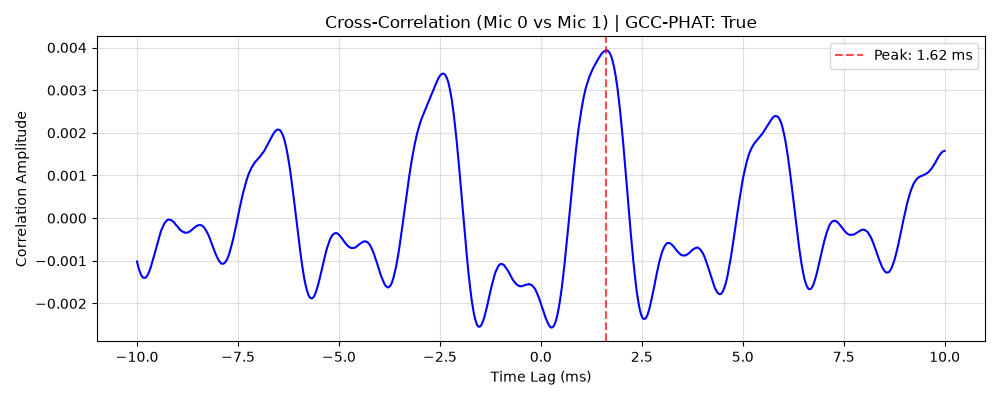

Ground truth positions:
 [[-0.55  0.45  0.45]
 [ 0.6  -0.4   0.65]]

Estimated positions:
 [[ 0.55 -0.55  0.4 ]
 [-0.5   0.5   0.45]]


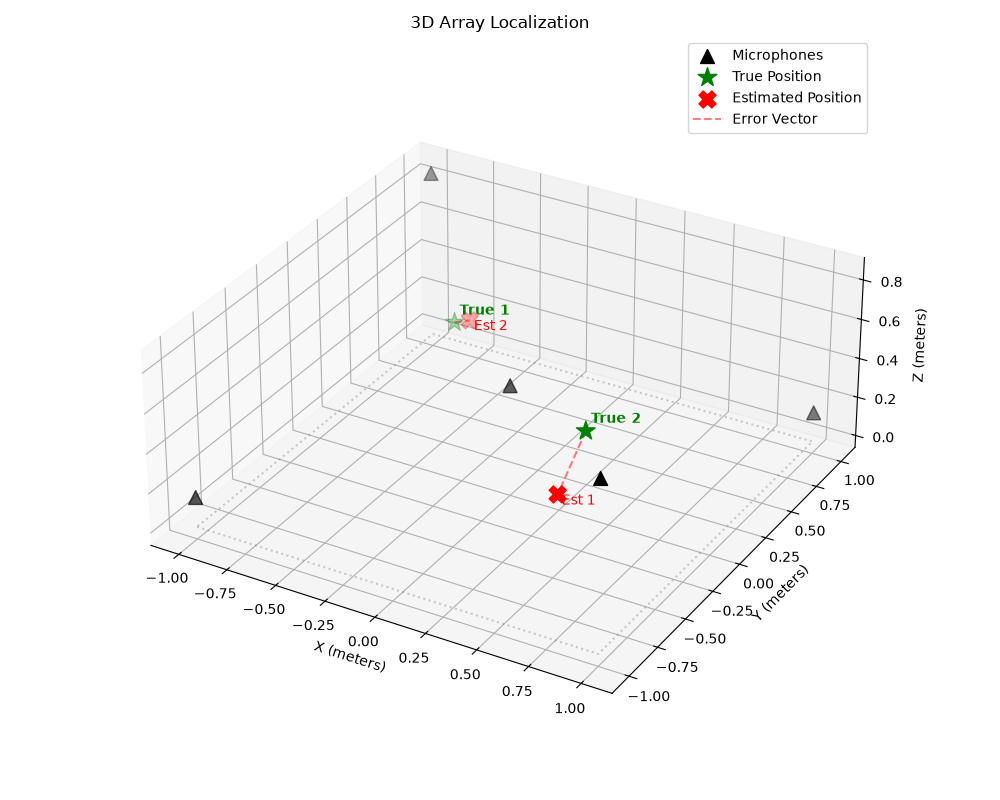

In [21]:
pos_a = np.array([-0.55, 0.45, 0.45])
pos_b = np.array([0.60, -0.40, 0.65])

sig_a = sim.generate_pollinator_buzz(duration=0.2, f0=250.0)
sig_b = sim.generate_pollinator_buzz(duration=0.2, f0=250.0)

rx_a, _ = sim.simulate_stationary_propagation(pos_a, mics, sig_a, snr_db=25)
rx_b, _ = sim.simulate_stationary_propagation(pos_b, mics, sig_b, snr_db=25)

# Safely zero-pad and sum recordings with different propagation tail lengths
rx_mixed = pad_sum(rx_a, rx_b)

# Take a middle 40 ms chunk (past the initial propagation delay)
window_samples = int(0.04 * sim.fs)
mid = rx_mixed.shape[1] // 2
chunk_mixed = rx_mixed[:, mid:mid + window_samples]

# Inspect the GCC-PHAT peaks between Mic 0 and Mic 1
plot_cross_correlation(chunk_mixed, fs=FS, ref_mic_idx=0, target_mic_idx=1, use_gcc_phat=True)

# Localize both targets
est_positions, _ = solver.srp_phat(chunk_mixed, mics, bounds=bounds, num_targets=2)

print("Ground truth positions:\n", np.vstack([pos_a, pos_b]))
print("\nEstimated positions:\n", est_positions)

plot_3d_geometry(mics, np.vstack((pos_a, pos_b)), est_positions)